# YOLOv8 vehicle tracking and single-line crossing counter

This notebook reads `d.mp4`, tracks vehicles using **YOLOv8 + ByteTrack**, draws bounding boxes and track IDs, and writes `output_single_line.mp4` with live crossing counts.

**Run all cells in order** using a Python notebook kernel with this project folder as its working directory. Select the project kernel as described below. The environment uses CPU inference. The first model load requires internet access to download `yolov8n.pt`.

The screenshot shows road traffic, so the default classes are bicycles, cars, motorcycles, buses and trucks. Set `CLASSES = None` to track all COCO object classes. The counting anchor is the bottom center of each bounding box. Each track ID is counted only once, in either direction. Objects already beyond the line at the start are not counted until they cross it. Occlusion and ID changes can affect accuracy.

API reference: [Ultralytics tracking documentation](https://docs.ultralytics.com/modes/track/).


In [1]:
# Dependencies are installed in the project .venv. No installation needed on each run.
# To recreate the environment, use requirements-notebook.txt (see setup notes).


## Select the project kernel before running

Select **YOLO (Python 3.12 CPU)**, or choose the Python interpreter `.venv/Scripts/python.exe` inside this project. Do not select the global `C:/Program Files/Python312/python.exe` kernel that produced the DLL error.

This isolated environment uses matched CPU packages `torch==2.8.0+cpu` and `torchvision==0.23.0+cpu`. It does not use the packages in your roaming Python installation. The import cell checks the interpreter before loading native libraries.

To recreate this environment from a PowerShell terminal in the project folder:

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements-notebook.txt
.\.venv\Scripts\python.exe -m ipykernel install --user --name yolo-cpu --display-name "YOLO (Python 3.12 CPU)"
```

[Official matched PyTorch versions](https://pytorch.org/get-started/previous-versions/) and [related Windows DLL issue](https://github.com/pytorch/pytorch/issues/166628).


In [2]:
import sys
from pathlib import Path
expected_python = (Path.cwd() / ".venv" / "Scripts" / "python.exe").resolve()
if Path(sys.executable).resolve() != expected_python:
    raise RuntimeError(
        f"Wrong notebook kernel: {sys.executable}\n"
        f"Select YOLO (Python 3.12 CPU), or select this interpreter: {expected_python}"
    )
import torch
print(f"Python: {sys.executable}")
print(f"PyTorch: {torch.__version__}; tensor check: {torch.ones(1).item()}")

from pathlib import Path
import math
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Video, FileLink
from tqdm.auto import tqdm
from ultralytics import YOLO

PROJECT_DIR = Path.cwd()
INPUT_PATH = PROJECT_DIR / "d.mp4"
OUTPUT_PATH = PROJECT_DIR / "output_single_line.mp4"
MODEL_PATH = "yolov8n.pt"
CLASSES = [1, 2, 3, 5, 7]  # COCO: bicycle, car, motorcycle, bus, truck
CONFIDENCE = 0.25
IMAGE_SIZE = 640
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Coordinates are fractions of the video dimensions; adjust after previewing.
LINE_Y_FRACTION = 0.65
LINE_X_START_FRACTION = 0.15
LINE_X_END_FRACTION = 0.98
DEADBAND_FRACTION = 0.01  # Ignore small movements immediately around the line.

if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"Place d.mp4 in the notebook working directory: {PROJECT_DIR}")
assert INPUT_PATH.resolve() != OUTPUT_PATH.resolve()
assert 0 < LINE_Y_FRACTION < 1
assert 0 <= LINE_X_START_FRACTION < LINE_X_END_FRACTION <= 1
assert 0 <= DEADBAND_FRACTION < 0.1
print(f"Input: {INPUT_PATH}\nOutput: {OUTPUT_PATH}\nDevice: {DEVICE}")


Python: C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\.venv\Scripts\python.exe
PyTorch: 2.8.0+cpu; tensor check: 1.0
Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Megha Prasad\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Input: C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\d.mp4
Output: C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\output_single_line.mp4
Device: cpu


## Preview the counting line

The yellow segment is the counting line. Dashed cyan lines show the jitter tolerance. Adjust the fractions above and rerun this preview if necessary. Only crossings within the yellow segment count. “Down” means movement toward the bottom of the image; “Up” means movement toward the top.


640 x 360, 23.976 FPS, approximately 687 frames


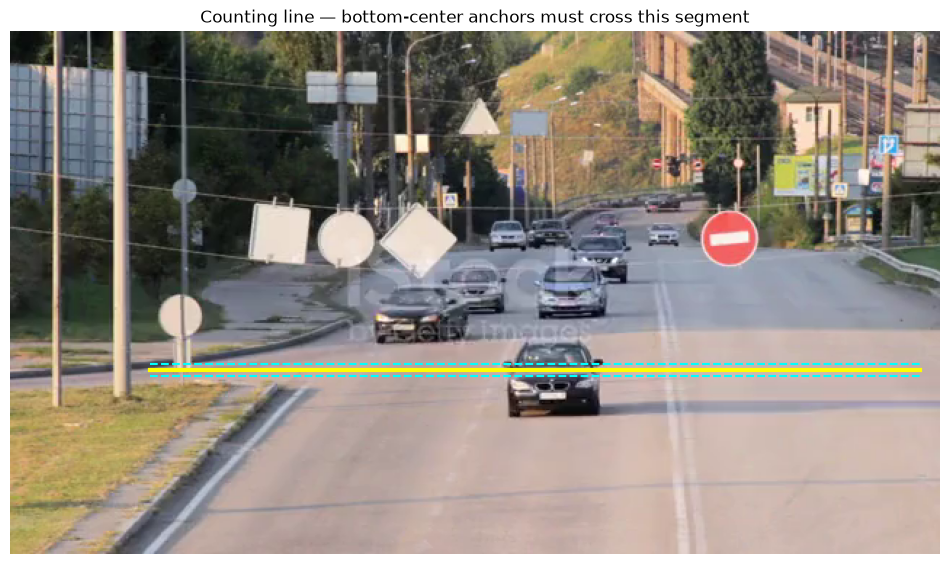

In [3]:
capture = cv2.VideoCapture(str(INPUT_PATH))
try:
    if not capture.isOpened():
        raise RuntimeError(f"Cannot open {INPUT_PATH}")
    ok, first_frame = capture.read()
    if not ok:
        raise RuntimeError("The input video has no readable frames.")
    height, width = first_frame.shape[:2]
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
finally:
    capture.release()

if not math.isfinite(fps) or fps <= 0:
    raise ValueError("Video FPS is invalid. Set fps manually to the source frame rate.")
line_y = round((height - 1) * LINE_Y_FRACTION)
x_start = round((width - 1) * LINE_X_START_FRACTION)
x_end = round((width - 1) * LINE_X_END_FRACTION)
deadband = max(1, round(height * DEADBAND_FRACTION))
print(f"{width} x {height}, {fps:.3f} FPS, approximately {frame_count} frames")
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
plt.plot([x_start, x_end], [line_y, line_y], color="yellow", linewidth=3)
for y in (line_y - deadband, line_y + deadband):
    plt.plot([x_start, x_end], [y, y], color="cyan", linestyle="--")
plt.title("Counting line — bottom-center anchors must cross this segment")
plt.axis("off")
plt.show()


## Crossing logic

Remember the last anchor outside the tolerance band. When an ID reaches the opposite side, interpolate the crossing location and check that it lies inside the line segment. This also handles motion that jumps across the line between frames. Discard stale positions after one second without a tracked observation. A counted-ID set prevents repeated counts from the same track.


In [4]:
class LineCrossingCounter:
    def __init__(self, y, x_start, x_end, deadband=3, max_gap=30):
        self.y = y
        self.x_start = x_start
        self.x_end = x_end
        self.deadband = deadband
        self.max_gap = max_gap
        self.previous = {}
        self.counted_ids = set()
        self.counts = {"up": 0, "down": 0}

    def update(self, track_id, x, y, frame_index):
        if track_id in self.counted_ids:
            return None
        side = -1 if y < self.y - self.deadband else (1 if y > self.y + self.deadband else 0)
        if side == 0:
            return None
        old = self.previous.get(track_id)
        self.previous[track_id] = (x, y, side, frame_index)
        if old is None:
            return None
        old_x, old_y, old_side, old_frame = old
        if frame_index - old_frame > self.max_gap or side == old_side:
            return None
        fraction = (self.y - old_y) / (y - old_y)
        crossing_x = old_x + fraction * (x - old_x)
        if self.x_start <= crossing_x <= self.x_end:
            direction = "down" if side == 1 else "up"
            self.counts[direction] += 1
            self.counted_ids.add(track_id)
            self.previous.pop(track_id, None)
            return direction
        return None

    def prune(self, frame_index):
        self.previous = {k: v for k, v in self.previous.items()
                         if frame_index - v[3] <= self.max_gap}


In [5]:
# Lightweight checks independent of model detections.
test = LineCrossingCounter(100, 20, 180, deadband=3, max_gap=10)
assert test.update(1, 50, 90, 0) is None
assert test.update(1, 50, 101, 1) is None  # Within the tolerance band.
assert test.update(1, 50, 110, 2) == "down"
assert test.update(1, 50, 80, 3) is None  # Same ID cannot count again.
assert test.update(2, 80, 110, 0) is None
assert test.update(2, 80, 90, 1) == "up"
assert test.update(3, 200, 90, 0) is None
assert test.update(3, 200, 110, 1) is None  # Outside the segment.
assert test.update(4, 80, 90, 0) is None
assert test.update(4, 80, 110, 20) is None  # Stale observation.
assert test.counts == {"up": 1, "down": 1}
print("Crossing logic checks passed.")


Crossing logic checks passed.


## Process and save the video

This cell creates a fresh model and counter each time it runs. It overwrites `output_single_line.mp4`. The output preserves the source resolution and frame rate; OpenCV does not copy audio. Wait for completion before opening the result. The progress bar reports processed frames.


In [6]:
model = YOLO(MODEL_PATH)
counter = LineCrossingCounter(line_y, x_start, x_end, deadband,
                              max_gap=max(1, round(fps)))
capture = cv2.VideoCapture(str(INPUT_PATH))
writer = None
processed = 0
last_annotated = None
try:
    if not capture.isOpened():
        raise RuntimeError(f"Cannot reopen {INPUT_PATH}")
    writer = cv2.VideoWriter(str(OUTPUT_PATH), cv2.VideoWriter_fourcc(*"mp4v"),
                             fps, (width, height))
    if not writer.isOpened():
        raise RuntimeError("Cannot initialize the MP4 writer. Check codec support and output permissions.")
    with tqdm(total=frame_count if frame_count > 0 else None, unit="frame") as progress:
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            result = model.track(frame, persist=True, tracker="bytetrack.yaml",
                                 classes=CLASSES, conf=CONFIDENCE, imgsz=IMAGE_SIZE,
                                 device=DEVICE, verbose=False)[0]
            annotated = result.plot()
            boxes = result.boxes
            if boxes is not None and boxes.id is not None:
                ids = boxes.id.int().cpu().tolist()
                coordinates = boxes.xyxy.cpu().tolist()
                for track_id, (x1, y1, x2, y2) in zip(ids, coordinates):
                    anchor_x, anchor_y = (x1 + x2) / 2, y2
                    counter.update(track_id, anchor_x, anchor_y, processed)
                    color = (0, 255, 0) if track_id in counter.counted_ids else (0, 200, 255)
                    cv2.circle(annotated, (round(anchor_x), round(anchor_y)), 4, color, -1)
            counter.prune(processed)
            cv2.line(annotated, (x_start, line_y), (x_end, line_y), (0, 255, 255), 3)
            total = sum(counter.counts.values())
            label = f"Crossed: {total}   Down: {counter.counts['down']}   Up: {counter.counts['up']}"
            font_scale = max(0.35, min(0.8, width / 1000))
            (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, 2)
            cv2.rectangle(annotated, (0, 0), (min(width - 1, text_width + 20), text_height + baseline + 20), (20, 20, 20), -1)
            cv2.putText(annotated, label, (10, text_height + 10), cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale, (255, 255, 255), 2, cv2.LINE_AA)
            writer.write(annotated)
            last_annotated = annotated
            processed += 1
            progress.update(1)
finally:
    capture.release()
    if writer is not None:
        writer.release()

if processed == 0:
    raise RuntimeError("No frames were processed.")
if frame_count > 0 and processed < frame_count:
    raise RuntimeError(f"Stopped early: decoded {processed}/{frame_count} frames. Output is partial.")
print(f"Saved {processed} frames to {OUTPUT_PATH}")
print(f"Total crossings: {sum(counter.counts.values())}; counts: {counter.counts}")


100%|██████████| 687/687 [01:34<00:00,  7.24frame/s]

Saved 687 frames to C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\output_single_line.mp4
Total crossings: 9; counts: {'up': 0, 'down': 9}


  0%|          | 0/687 [00:00<?, ?frame/s]

  0%|          | 1/687 [00:08<1:32:26,  8.09s/frame]

  0%|          | 2/687 [00:08<39:03,  3.42s/frame]  

...

100%|█████████▉| 685/687 [01:32<00:00,  7.83frame/s]

100%|█████████▉| 686/687 [01:32<00:00,  7.84frame/s]

100%|██████████| 687/687 [01:33<00:00,  7.98frame/s]

100%|██████████| 687/687 [01:33<00:00,  7.38frame/s]

Saved 687 frames to C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\output_single_line.mp4
Total crossings: 9; counts: {'up': 0, 'down': 9}


## Verify and preview the result

The next cell checks that the output can be decoded and contains the expected number of frames. Some notebook browsers cannot play OpenCV's `mp4v` codec; if playback is blank, open the linked MP4 in a local video player. A final-frame preview is also shown below.


Verified 687 output frames; file size: 8,057,580 bytes


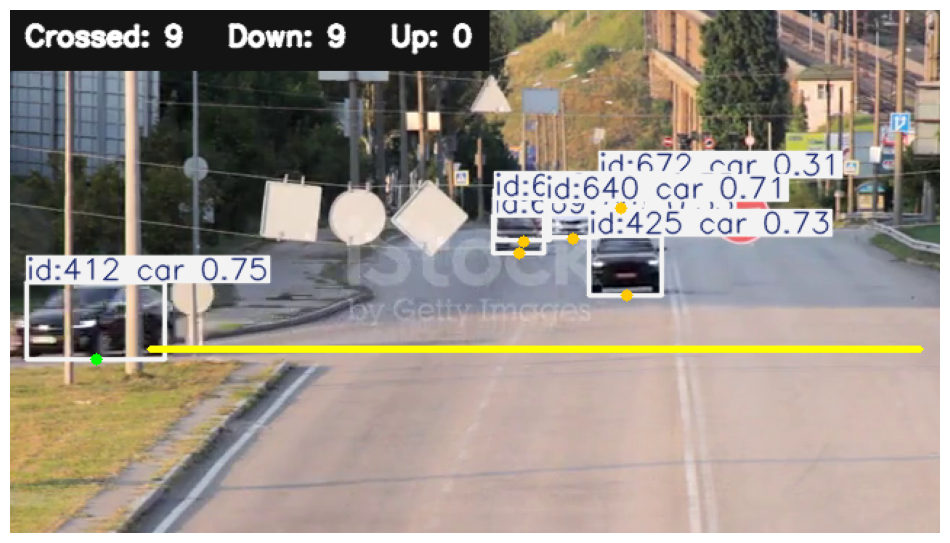

C:\Users\Megha Prasad\Documents\Projects\Github\YOLO\output_single_line.mp4

In [8]:
check = cv2.VideoCapture(str(OUTPUT_PATH))
output_frames = 0
try:
    if not check.isOpened():
        raise RuntimeError("Saved video cannot be opened.")
    while True:
        ok, decoded = check.read()
        if not ok:
            break
        assert decoded.shape[:2] == (height, width), "Unexpected output dimensions"
        output_frames += 1
finally:
    check.release()
assert output_frames == processed, f"Expected {processed} output frames, decoded {output_frames}"
print(f"Verified {output_frames} output frames; file size: {OUTPUT_PATH.stat().st_size:,} bytes")
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(last_annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
display(FileLink(OUTPUT_PATH.name))
display(Video(str(OUTPUT_PATH), embed=True, width=min(width, 960)))
